### Simple environment
using random jamming, single action instead of dual for simplicity (1 action , identified by freq * power)


In [2]:
import gymnasium as gym
import numpy as np
import random as random
from gymnasium import spaces
from gymnasium.envs.registration import register     #name the env
from gymnasium.utils.env_checker import check_env   #check if the env follows the gym API   
import matplotlib.pyplot as plt
from IPython.display import display
import time

#make the name of the env
register(
    id='AntiJammingEnv-v0',                         #name of the env when we instatiate
    # entry_point="simplenv.ipynb:AntiJammingEnv",   #module name:class name
    entry_point= lambda **kwargs: AntiJammingEnv(**kwargs),  #if the class is in the same file, we can use lambda
)


class AntiJammingEnv(gym.Env):
    # used to render the env
    metadata = {"render_modes": ["human"], "render_fps": 4}


    def __init__(self, num_freqs=22, num_powers=50, num_of_jammers=7, jammer_type="sweeping", render_mode=None):
        super().__init__()
        self.num_freqs = num_freqs
        self.num_powers = num_powers
        self.jammer_type = jammer_type          #random in this env
        self.num_of_jammers = num_of_jammers    # 7 random jammers
        self._sweep_step = 1             # how many bins to move per step for sweeping jammer
        self.power_levels = np.linspace(1.58e-4, 1e-3, num_powers)  # power levels from -8dbm to 0dbm converted to watts , taken from the paper (50 levels)
        self.jammer_power = 3.162e-3 # Jammer power 3.162e-3 W = 5 dBm from Table 1 in the paper

        #modifications to state
        self.state = None                 # current observation (PSD vector)
        self.state_dim = num_freqs + 1  #PSD + prev_freq , no prev_crc
        self.prev_freq = None           #need for freq switching penalty
        # self.prev_crc = None            #new
    
        # moved from step() to be class variables
        self.power_noise  = 3.162e-16      # NEW (kTB*N; matches your comment)
        self.alpha_k_user   = 9.1e-12        # NEW (Rayleigh scale for user)
        self.alpha_k_jammer = 1.15e-12       # NEW (Rayleigh scale for jammer)
        self._gain_user   = np.zeros(self.num_freqs)   # NEW (slot user gains)
        self._gain_jammer = np.zeros(self.num_freqs)   # NEW (slot jammer gains)


        #all rendering related variables
        self.render_mode = render_mode
        self._fig = None
        self._ax = None
        self._jam_bars = None
        self._agent_line = None
        self._power_text = None
        self._last_action = None
        self._last_reward = None
        self._total_reward = 0.0
        self.agent_marker = None
        self._display_handle = None


        # Define action space (freq × power combinations)
        # 22 * 50 = 1100 discrete actions (0..1099)
        # too many actions for DQN, but OK for policy gradient methods
        self.action_space = spaces.Discrete(num_freqs * num_powers)
        # self.action_space = spaces.MultiDiscrete([self.num_freqs, self.num_powers])

        # State = PSD (vector of size num_freqs)
        self.observation_space = spaces.Box(
            low=0.0, high=1.0, shape=(self.state_dim,), dtype=np.float32
        )

        #self.rng = random number generator
        self.rng = np.random.default_rng()

        # Internal jammer state & dynamics parameters
        self._jam_idxs = []             # indices of the currently jammed frequency bins


    def _build_state_from_jammer(self):
        """
        Construct the PSD observation vector given the *current* jammers indecies.
        - Background noise self.power_noise (kTB*NF from paper, e-16 range) plus 5% gaussian noise
        - Fixed scaling (stationary across steps) to fit in state space (0..1)
        
        This function is used in both `reset()` and `step()` so that
        the observation is always generated consistently.
        """
        s = np.full(self.num_freqs, self.power_noise)   # background noise = power noise (kTBN)

        if len(self._jam_idxs) == 0:       # choose jammer indices if not already chosen           
            self._jam_idxs = self.np_random.choice(range(self.num_freqs), size=self.num_of_jammers, replace=False).tolist()

        # set jammer powers
        jam_idxs_array = np.array(self._jam_idxs, dtype=int)  # helper array to avoid for loop to set each jammer power
        s[jam_idxs_array] += self.jammer_power * self._gain_jammer[jam_idxs_array] # psd = jammer power + noise 

        # add gaussian measurement noise and clip at low floor
        s = s * (1.0 + 0.05 * self.rng.standard_normal(self.num_freqs))
        s = np.clip(s, self.power_noise * 0.5, None)

        # FIXED scaling (stationary across steps)
        # ~95% jammed values lie within headroom when gains are exponential
        headroom = self.jammer_power * self.alpha_k_jammer * 3.0
        denom = max(headroom, 1e-30)
        s_normalized = (s - self.power_noise) / denom
        s_normalized = np.clip(s_normalized, 0.0, 1.0)

        # add prev_freq and prev_crc to the state
        prev_f_norm = 0.0 if self.prev_freq is None else self.prev_freq / (self.num_freqs - 1)
        full_state  = np.concatenate([s_normalized, [prev_f_norm]], axis=0)

        return full_state.astype(np.float32)
    
    

    def _advance_jammer(self):
        """
        Update the jammer index based on jammer_type dynamics:
        - fixed: jammer never moves
        - sweeping: jammer shifts to the next bin each step
        - random: jammer picks a new random bin every step
        """

        jt = self.jammer_type.lower()
        if jt == "fixed":
            pass  # jammer stays in the same bin forever

        elif jt == "sweeping":
            for i in range(len(self._jam_idxs)):
                #modulo to wrap around (23 -> 1 for example)
                self._jam_idxs[i] = (self._jam_idxs[i] + self._sweep_step) % self.num_freqs

        elif jt == "random":
            # for i in range(len(self._jam_idxs)):
            #     self._jam_idxs[i] = int(self.rng.integers(0, self.num_freqs)) May lead to duplicates
            self._jam_idxs = self.rng.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist()  # NEW



    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)

        # Initialize jammer index and build the first observation
        # used self.np_random that apparently got initted by super().reset(seed=seed)

        #new reset function
        self._jam_idxs = self.np_random.choice(self.num_freqs, size=self.num_of_jammers, replace=False).tolist() 
        self._gain_user   = self.alpha_k_user   * -1 * np.log(self.rng.random(self.num_freqs))  # NEW, needs to be initialized for s0
        self._gain_jammer = self.alpha_k_jammer * -1 * np.log(self.rng.random(self.num_freqs))  # NEW, needs to be initialized for s0

        self.prev_freq = None
        self.prev_crc  = 0.0
        self.state = self._build_state_from_jammer()

        info = {}

        #rendering related book-keeping
        self._last_state = self.state      # so first render works
        self._last_action = None
        self._last_reward = None

        return self.state.astype(np.float32), info
    



    def step(self, action):
        """
        One-slot delay logic:
        - Agent picked `action` using observation s_k (= self._last_state).
        - Environment first advances jammer to unseen slot k+1 and measures s_{k+1}.
        - Reward is computed against s_{k+1} (the actual slot you just transmitted in).
        - Next observation returned to agent is s_{k+1}.
        """
        # Decode (freq, power)
        freq = action // self.num_powers
        power = action % self.num_powers   # 1..num_powers
        # freq, power = map(int, action)  #power here is the index of the power level
        power = self.power_levels[power]

        self._gain_user   = self.alpha_k_user   * -1 * np.log(self.rng.random(self.num_freqs))  # NEW
        self._gain_jammer = self.alpha_k_jammer * -1 * np.log(self.rng.random(self.num_freqs))  # NEW

        #for simplicity and faithfulness to old code
        # alpha_k_user   = self.alpha_k_user   # from SNR_clean target (≈12 dB)
        # alpha_k_jammer = self.alpha_k_jammer  # from desired jammed SINR (≈0 dB)
        gain_vector_user = self._gain_user # channel gain vector for all frequencies sampled each step 
        gain_vector_jammer = self._gain_jammer # channel gain vector for all frequencies sampled each step
          


        # === Move to *new* (unseen) slot and measure PSD_{k+1} ===
        #uncomment this 2 lines for 1slot delay
        self._advance_jammer()
        curr_psd = self._build_state_from_jammer()    # s_{k+1}

        #uncomment this line for 0slot delay
        # curr_psd = self.state  # s_{k}

        # --- Compute reward using the *current* slot conditions (which were not observed before acting) ---
        jammed = (freq in self._jam_idxs)  # NEW
        powerNoise = self.power_noise     # NEW
        jamming_power = self.jammer_power * gain_vector_jammer[freq] if jammed else 0.0 # if jammer is present, its power is 3.162e-3 W (5 dBm) * gain of jammer as in the paper, else very small power 1e-10 W
        sinr = (power*gain_vector_user[freq]) / (powerNoise+jamming_power+1e-30)

        #crc calculation
        beta_th = 10**(6/10)  # SINR threshold for successful CRC, it is taken from GPT as a standard practice with QPSK modulation, but can be manipulated between 6-10 dbm , this shows 8dbm
        # right before crc_success line
        den = powerNoise + (self.jammer_power * gain_vector_jammer[freq] if jammed else 0.0)
        sinr = (power * gain_vector_user[freq]) / (den + 1e-30)
        sinr_db = 10*np.log10(sinr + 1e-30)
        # print(f"clean={not jammed} P={power:.2e} gU={gain_vector_user[freq]:.2e} den={den:.2e} SINR={sinr_db:.2f}dB pass={sinr>beta_th}")
        crc_success = 1.0 if sinr > beta_th else 0.0

        # Switching penalty (compare with last used freq)   
        switching_penalty = 0.0
        if self.prev_freq is not None and self.prev_freq != freq:
            switching_penalty = 1.0
        
    
        lambd = 600
        # subBandWidth = 25e3 # 25 kHz , taking from the paper that the base is 20 kHz and some roll-off margin
        # epsilon = 1e4 # taken from GPT, suggested to make the affect of the power in the same scale with swithcing and etc.. 
        alpha = 1.2# weight for switching penalty from the paper Table 1
        # reward =  crc_success * (subBandWidth * np.log2(1 + sinr)) / (epsilon * power) - alpha * switching_penalty
        reward = crc_success * ((np.log2(1 + sinr))) - lambd * power - alpha * switching_penalty



        # reward = (crc_success * (((subBandWidth * np.log2(1+sinr))/(epsilon*power))))-(alpha*switching_penalty)
#             print(
#     f"\n[Step Debug]"
#     f"\nFreq: {freq} | Power (W): {power:.3e} | PSD@Freq: {noise_at_chosen:.2f} "
#     f"| Jammed: {noise_at_chosen>0.9}"
#     f"\nUserGain: {gain_vector_user[freq]:.3e} | JammerGain: {gain_vector_jammer[freq]:.3e}"
#     f"\nSINR: {sinr:.3e} | SINR_dB: {10*np.log10(sinr+1e-12):.2f} dB"
#     f"\nCRC: {crc_success} | SwitchPenalty: {switching_penalty}"
#     f"\nReward: {reward:.6f} | TotalReward: {self._total_reward + reward:.6f}"
# )

        # Update previous freq
        self.prev_freq = freq
        # self.prev_crc = float(crc_success)

        # === One-slot-delay book-keeping ===
        # Next observation is the PSD we just measured in this slot.
        
        #uncomment this for 1slot delay
        self._last_state = curr_psd      # used for rendering
        self.state = curr_psd

        #uncomment this for 0slot delay
        # self._advance_jammer()
        # next_state = self._build_state_from_jammer()   # s_{k+1}
        # self.state = next_state

        terminated = False
        truncated = False
        info = {
            "crc_success": float(crc_success),      # 0 / 1
            "switched":    float(switching_penalty > 0),  # 0 / 1
            "power_w":     float(power)             # chosen power (W)
        }

        #rendering related book-keeping
        self._last_action = (freq, power)
        self._last_reward = float(reward)
        self._total_reward = self._total_reward + reward
        if self.render_mode == "human":
            self.render()
        
        return self.state.astype(np.float32), reward, terminated, truncated, info


    def render(self):
        if self.render_mode != "human":
            return

        # ── show the PSD from the slot where the last action was used ────────────
        psd_to_show = self._last_state[:self.num_freqs] if getattr(self, "_last_state", None) is not None else self.state[:self.num_freqs]
        # ─────────────────────────────────────────────────────────────────────────

        # Lazily build the figure once
        if self._fig is None or not plt.fignum_exists(self._fig.number):
            plt.ioff()
            self._fig, self._ax = plt.subplots(figsize=(10, 4))
            self._ax.set_title("Anti-jamming spectrum (live)")
            self._ax.set_xlabel("Frequency bin")
            self._ax.set_ylabel("PSD / jammer power")
            self._ax.set_ylim(0.0, 1.2)
            self._ax.set_xlim(-0.5, self.num_freqs - 0.5)

            self._jam_bars = self._ax.bar(
                range(self.num_freqs),
                psd_to_show if psd_to_show is not None else np.zeros(self.num_freqs),
                color="#1f77b4",
                alpha=0.75,
            )
            self._agent_marker = self._ax.scatter(
                [], [], s=120, color="#ff7f0e", edgecolor="black", zorder=5
            )
            self._power_text = self._ax.text(
                0.01, 0.97, "Awaiting first action",
                transform=self._ax.transAxes,
                fontsize=11, va="top",
                bbox=dict(boxstyle="round", facecolor="white", alpha=0.85),
            )
            self._fig.canvas.draw()
            self._display_handle = display(self._fig, display_id=True)

        # ── update jammer bars ────────────────────────────────────────────────────
        if psd_to_show is not None:
            for bar, height in zip(self._jam_bars, psd_to_show):
                bar.set_height(height)
                bar.set_color("#d62728" if height > 0.9 else "#1f77b4")

        # ── update agent marker & annotation ──────────────────────────────────────
        if self._last_action is not None:
            freq, power_w = self._last_action
            self._agent_marker.set_offsets([[freq, psd_to_show[freq]]])

            lines = [
                f"Agent freq = {freq}",
                f"Power = {power_w:.2e} W",
            ]
            if self._last_reward is not None:
                lines.append(f"Reward = {self._last_reward:.3f}")
            if self._total_reward is not None:
                lines.append(f"Total = {self._total_reward:.3f}")

            self._power_text.set_text("\n".join(lines))
        else:
            self._agent_marker.set_offsets([])
            self._power_text.set_text("Awaiting first action")

        # ── draw & throttle frame rate ────────────────────────────────────────────
        self._fig.canvas.draw()
        if self._display_handle is not None:
            self._display_handle.update(self._fig)
            time.sleep(0.8)


### ONLY FOR PLOTTING THE REWARD FUNCTION FULLY ### 

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# =========================
# Config (aligns with your env)
# =========================
B = 25e3                          # Hz (bandwidth)
epsilon = 1.5e8                   # energy scaling
beta_th = 10**(8/10)              # CRC threshold (8 dB, linear)
noise_power = 3.162e-16           # W (kTB * NF for 25 kHz, NF=5 dB)
jammer_power = 3.162e-3           # W (5 dBm)
alpha_k_user   = 9.1e-12          # mean user gain (calibrated)
alpha_k_jammer = 1.15e-12         # mean jammer gain (calibrated)

# Sweep ranges (ascending as requested)
freqs = np.arange(1, 23)                      # 1..22
powers_dbm = np.linspace(-8, 0, 50)           # dBm, ascending
powers_w = 1e-3 * 10**(powers_dbm / 10.0)     # W, ascending

rng = np.random.default_rng(123)

# =========================
# Reward definition (no switch penalty here to show the surface cleanly)
# r = phi * (B * log2(1 + SINR) / (epsilon * P))
# SINR = (P * g_user) / (noise_power + I_jam)
# =========================
def reward_single(power_w, jammed, g_user, g_jam):
    I_jam = jammer_power * g_jam if jammed else 0.0
    sinr = (power_w * g_user) / (noise_power + I_jam)
    phi = 1.0 if sinr > beta_th else 0.0
    throughput = B * np.log2(1.0 + sinr)
    return phi * (throughput / (epsilon * power_w))

def sample_gain_user():
    return rng.exponential(scale=alpha_k_user)

def sample_gain_jam():
    return rng.exponential(scale=alpha_k_jammer)

# =========================
# Plot 1: Reward vs Power (for multiple freqs) — clean and jammed
# =========================
def plot_reward_vs_power(selected_freqs=(1,5,10,15,20,22), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for f in selected_freqs:
        # Fix gains per curve to avoid noisy wiggles across the sweep
        g_u = sample_gain_user()
        g_j = sample_gain_jam()
        rewards = [reward_single(pw, jammed, g_u, g_j) for pw in powers_w]
        plt.plot(powers_dbm, rewards, label=f"Freq {f} {(g_u/g_j):.2e}")
    plt.xlabel("Power (dBm)")                    # −8 → 0 (ascending)
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Power {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Plot 2: Reward vs Frequency (for multiple powers) — clean and jammed
# =========================
def plot_reward_vs_frequency(selected_p_dbm=(-8, -6, -4, -2, 0), jammed=False, title_suffix=""):
    plt.figure(figsize=(8, 6))
    for p_dbm in selected_p_dbm:
        p_w = 1e-3 * 10**(p_dbm / 10.0)
        # New gains per-frequency to reflect independent fading across bins
        rewards = []
        for _ in freqs:  # 1 → 22 (ascending)
            g_u = sample_gain_user()
            g_j = sample_gain_jam()
            rewards.append(reward_single(p_w, jammed, g_u, g_j))
        plt.plot(freqs, rewards, label=f"P={p_dbm} dBm")
    plt.xlabel("Frequency bin (1 → 22)")
    plt.ylabel("Reward (no switch)")
    plt.title(f"Reward vs Frequency {title_suffix}".strip())
    plt.grid(True)
    plt.legend()
    plt.show()

# =========================
# Usage examples (uncomment the ones you want)
# =========================
plot_reward_vs_power(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_power(jammed=True,  title_suffix="(Jammed bins)")
plot_reward_vs_frequency(jammed=False, title_suffix="(Clean bins)")
plot_reward_vs_frequency(jammed=True,  title_suffix="(Jammed bins)")


### Check random policy for a few episodes


In [ ]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = env.action_space.sample()
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


## create a greedy policy (no RL in greedy, just to see if RL works)
decode action is a helper function to return freq and power from single action space of freq * power

In [ ]:
def greedy_policy(obs, env, sinr_thresh_db: float = 8.0):
    """
    One-step optimal (delay-free) greedy policy:
      - looks at the current PSD observation `obs`
      - evaluates every (freq, power) pair with *exactly* the same
        reward calculation used in env.step()
      - returns the arg-max action index.

    Assumes env exposes:
        num_freqs, num_powers, power_levels (list of W),
        jammer_power, prev_freq (or None).
    The physical/constants mirror those in env.step().
    """
    obs = np.asarray(obs, dtype=np.float64)

    # --- constants identical to env.step() -----------------------------
    alpha_k_user   = 9.1e-12           # mean Rayleigh gain used in paper
    power_noise    = 3.162e-16         # kT·NF for 25 kHz, NF=5 dB
    sub_bandwidth  = 25e3              # 25 kHz
    epsilon        = 1.5e8             # paper’s scaling factor for rate term
    alpha_switch   = 0.5               # switching-penalty weight (Table I)
    beta_th        = 10 ** (sinr_thresh_db / 10.0)
    # -------------------------------------------------------------------

    best_reward  = -np.inf
    best_action  = 0
    prev_freq    = env.prev_freq 

    for f in range(env.num_freqs):
        # “Jammed” flag exactly as in env.step()
        is_jammed      = obs[f] > 0.9
        jamming_power  = env.jammer_power if is_jammed else 0.0

        switch_penalty = alpha_switch if (prev_freq is not None and prev_freq != f) else 0.0

        for p_idx, p_watt in enumerate(env.power_levels):

          
            # Use *expected* channel gain (alpha_k_user) – agent can’t see fast-fading
            sinr         = (p_watt * alpha_k_user) / (power_noise + jamming_power)
            crc_success  = int(sinr > beta_th)

            reward = crc_success * (sub_bandwidth * np.log2(1.0 + sinr)) / (epsilon * p_watt) - switch_penalty

            if reward > best_reward:
                best_reward = reward
                best_action = f * env.num_powers + p_idx
                #uncomment below for dual action space
                # best_action = np.array([f, p_idx], dtype=np.int64)

            # Early exit: once we find a power that clears CRC with no switch penalty,
            # lower powers (higher idx) will only reduce reward.
            if crc_success == 1.0 and switch_penalty == 0.0:
                break

    return best_action


### Check greedy policy for few episodes

In [ ]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action = greedy_policy(obs, base_env)
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


### instantiate env and agent (DQN) to learn for 200_000 steps

In [ ]:
import gymnasium as gym
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit

from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor
from stable_baselines3.common.callbacks import EvalCallback

def make_env():
    env = gym.make("AntiJammingEnv-v0", render_mode=None)
    env = RecordEpisodeStatistics(env)
    env = gym.wrappers.TimeLimit(env, max_episode_steps=200)

    return env

vec_env = DummyVecEnv([make_env])   #make one training env
vec_env = VecMonitor(vec_env)

eval_env = DummyVecEnv([make_env]) #make one eval env
eval_env = VecMonitor(eval_env)



model = DQN(
    policy="MlpPolicy",
    env=vec_env,
    learning_rate=5e-5,
    buffer_size=100_000,        # replay buffer size
    learning_starts=10_000,     # delay gradient updates until the buffer has this many samples
    batch_size=512,
    gamma=0.99,
    target_update_interval=1_000,
    train_freq=(4, "step"),
    exploration_fraction=0.2,
    exploration_initial_eps=1.0,
    exploration_final_eps=0.05,
    verbose=1,
    tensorboard_log="runs/anti_jam_dqn",
    device="auto",
)

eval_cb = EvalCallback(
    eval_env,
    eval_freq=5_000,
    n_eval_episodes=10,
    deterministic=True
)

model.learn(
    total_timesteps=200_000,
    log_interval=100,          # <= IMPORTANT
    callback=eval_cb
)


In [ ]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


# Eval callback

In [6]:
from stable_baselines3.common.callbacks import BaseCallback
import numpy as np

class MetricsCallback(BaseCallback):
    """
    Logs switch-rate, CRC success, and mean power to TensorBoard.
    """
    def __init__(self, log_every=1000):
        super().__init__(verbose=0)
        self.log_every = log_every
        self._reset_acc()

    def _reset_acc(self):
        self.n_steps = 0
        self.n_switch = 0
        self.n_crc = 0
        self.sum_power = 0.0

    def _on_step(self) -> bool:
        # "infos" is a list (one per parallel env)
        for info in self.locals["infos"]:
            self.n_steps   += 1
            self.n_switch  += info.get("switched", 0.0)
            self.n_crc     += info.get("crc_success", 0.0)
            self.sum_power += info.get("power_w", 0.0)

        # flush to TensorBoard every log_every env steps
        if self.n_calls % self.log_every == 0 and self.n_steps > 0:
            self.logger.record("custom/switch_rate",
                               self.n_switch / self.n_steps)
            self.logger.record("custom/crc_success",
                               self.n_crc / self.n_steps)
            self.logger.record("custom/mean_power",
                               self.sum_power / self.n_steps)
            self.logger.dump(self.n_calls)      # push to TB
            self._reset_acc()
        return True


# Train PPO
 - notes: uses normalized rewards and observations
 - deterministic = False when evaluating since PPO outputs prob distrubution for actions and then samples from it

In [ ]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor, VecNormalize
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit
from stable_baselines3.common.callbacks import EvalCallback


def make_env():
    env = gym.make("AntiJammingEnv-v0", render_mode=None)
    env = RecordEpisodeStatistics(env)
    env = TimeLimit(env, max_episode_steps=200)   # should be paper’s K
    return env

train_env = DummyVecEnv([make_env])
train_env = VecMonitor(train_env)
train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True)

eval_env  = DummyVecEnv([make_env])
eval_env  = VecMonitor(eval_env)
eval_env  = VecNormalize(eval_env, training=False)

model = PPO(
    "MlpPolicy",
    train_env,
    learning_rate=1e-4,
    n_steps=256,          # 5 full episodes per rollout
    batch_size=512,
    gamma=0.99,
    gae_lambda=0.95,
    clip_range=0.2,
    tensorboard_log="runs/anti_jam_ppo",
    verbose=1,
    device="auto",
    max_grad_norm=0.5,
    # ent_coef = 0.0001
    ent_coef=0.01,          # NEW: exploration bonus
    n_epochs=10,    #default is 4
    target_kl=0.02,          # NEW: stop overly big policy jumps
)

eval_cb = EvalCallback(
    eval_env,
    eval_freq=5_000,
    n_eval_episodes=10,
    deterministic=True
)

metrics_cb = MetricsCallback(log_every=1000)     # 1000 env-steps per point
model.learn(
 total_timesteps=200_000,
 log_interval=100,
 callback=[eval_cb, metrics_cb]
)


Using cpu device


/Users/mar5/vscode/DRL/.venv/lib/python3.13/site-packages/stable_baselines3/ppo/ppo.py:155: UserWarning: You have specified a mini-batch size of 512, but because the `RolloutBuffer` is of size `n_steps * n_envs = 256`, after every 0 untruncated mini-batches, there will be a truncated mini-batch of size 256
We recommend using a `batch_size` that is a factor of `n_steps * n_envs`.
Info: (n_steps=256 and n_envs=1)
  warnings.warn(


Logging to runs/anti_jam_ppo/PPO_5
-------------------------------------------
| custom/                 |               |
|    crc_success          | 0.599         |
|    mean_power           | 0.00059       |
|    switch_rate          | 0.955         |
| train/                  |               |
|    approx_kl            | 0.00027170847 |
|    clip_fraction        | 0             |
|    clip_range           | 0.2           |
|    entropy_loss         | -7            |
|    explained_variance   | -3.38         |
|    learning_rate        | 0.0001        |
|    loss                 | 0.234         |
|    n_updates            | 30            |
|    policy_gradient_loss | -0.00914      |
|    value_loss           | 0.678         |
-------------------------------------------
-------------------------------------------
| custom/                 |               |
|    crc_success          | 0.573         |
|    mean_power           | 0.000574      |
|    switch_rate          | 0.946        

# SubProcEnv


In [9]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import SubprocVecEnv, VecMonitor, VecNormalize
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit
from stable_baselines3.common.callbacks import EvalCallback
# Import the class from the file we just created
from antijam_env import AntiJammingEnv

# Configuration
N_ENVS = 8              # Parallel environments (Good for M2 Pro)
N_STEPS = 1024          # Steps per env per update (Total buffer = 8 * 1024 = 8192)
BATCH_SIZE = 2048       # Mini-batch size (Factor of 8192)

def make_env(rank, seed=0):
    """
    Utility function for multiprocessed env.
    :param rank: index of the subprocess
    :param seed: the initial seed for RNG
    """
    def _init():
        # Instantiate directly (no gym.make needed if imported)
        env = AntiJammingEnv(render_mode=None)
        
        # Wrappers
        env = RecordEpisodeStatistics(env)
        env = TimeLimit(env, max_episode_steps=200)
        
        # Important: Seed each environment differently
        env.reset(seed=seed + rank)
        return env
    return _init

if __name__ == "__main__":
    # Create the vectorized environment
    # start_method="spawn" is default on Mac, but "fork" is faster if it doesn't crash.
    # Safest to stick to default (spawn) with the class in a separate file.
    train_env = SubprocVecEnv([make_env(i) for i in range(N_ENVS)])
    
    # Wrap for monitoring and normalization
    train_env = VecMonitor(train_env)
    train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True)

    # Eval env can stay serial (DummyVecEnv) as it's just for checking performance
    eval_env = SubprocVecEnv([make_env(100)]) # Or DummyVecEnv([make_env(100)])
    eval_env = VecMonitor(eval_env)
    eval_env = VecNormalize(eval_env, training=False)

    model = PPO(
        "MlpPolicy",
        train_env,
        learning_rate=1e-4,         # Standard starting rate
        n_steps=N_STEPS,            # Increased to gather more samples before updating
        batch_size=BATCH_SIZE,      # Increased to match larger buffer
        gamma=0.99,
        gae_lambda=0.95,
        clip_range=0.2,
        tensorboard_log="runs/anti_jam_ppo",
        verbose=1,
        device="auto",
        max_grad_norm=0.5,
        ent_coef=0.01,
        n_epochs=10,
        target_kl=0.02,
    )

    eval_cb = EvalCallback(
        eval_env,
        eval_freq=5000 // N_ENVS,   # Adjust freq because 1 step = 8 env steps
        n_eval_episodes=10,
        deterministic=True
    )

    metrics_cb = MetricsCallback(log_every=1000 // N_ENVS)

    print(f"Training on {N_ENVS} parallel environments...")
    model.learn(
        total_timesteps=2_000_000,  # Scaled up as per recommendation (2M is a good start)
        log_interval=10,            # Log more frequently in wall-time
        callback=[eval_cb, metrics_cb]
    )
    
    # Save the model and normalization stats
    # model.save("ppo_antijam_parallel")
    # train_env.save("vec_normalize.pkl")

Using cpu device
Training on 8 parallel environments...
Logging to runs/anti_jam_ppo/PPO_7
-----------------------------
| custom/        |          |
|    crc_success | 0.577    |
|    mean_power  | 0.000579 |
|    switch_rate | 0.946    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.599    |
|    mean_power  | 0.000587 |
|    switch_rate | 0.947    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.552    |
|    mean_power  | 0.000569 |
|    switch_rate | 0.961    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.574    |
|    mean_power  | 0.000575 |
|    switch_rate | 0.955    |
-----------------------------
Eval num_timesteps=5000, episode_reward=157.66 +/- 45.16
Episode length: 200.00 +/- 0.00
---------------------------------
| eval/              |          |
|    mean_ep_length  | 200      

# visualize e


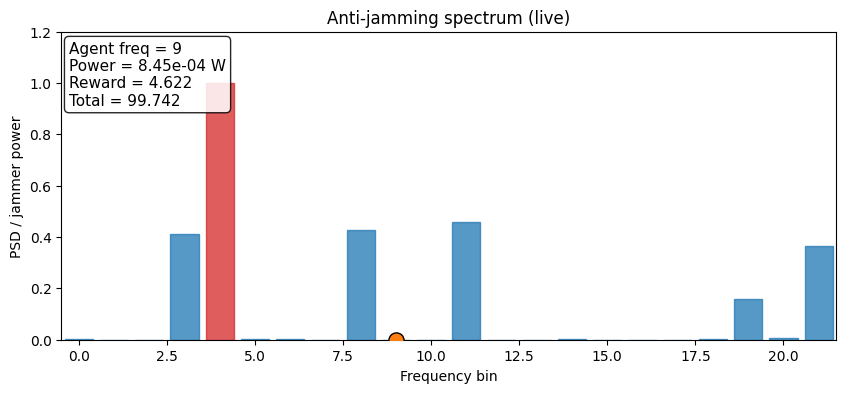

KeyboardInterrupt: 

In [10]:
import gymnasium as gym

num_episodes = 30
max_steps = 200
cumulative_reward_over_episodes = 0.0


env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)
base_env = env.unwrapped


for ep in range(num_episodes):
    obs, info = env.reset()
    total_reward = 0.0

    for step in range(max_steps):
        action, _ = model.predict(obs, deterministic=True)  #no deterministic for PPO
        obs, reward, terminated, truncated, info = env.step(action)

        total_reward += reward

        if terminated or truncated:
            break

    print(f"Episode {ep+1}: return={total_reward:.2f}, steps={step+1}") if (ep+1) % 5 == 0 else None
    cumulative_reward_over_episodes += total_reward


print(f"Mean reward over episodes: {cumulative_reward_over_episodes / num_episodes:.2f}")
env.close()


# stats


In [11]:
# ============ Comprehensive Evaluation Cell ============
import gymnasium as gym
from gymnasium.wrappers import TimeLimit
import numpy as np

# --- REQUIREMENTS ---
assert 'model' in globals(), "Run your PPO training cell first (must define `model`)."

# --- CONFIG (adjust if needed) ---
N_EPISODES   = 20
MAX_STEPS    = 200
DETERMINISTIC= True
RENDER       = False
BETA_DB      = 6.0               # use your current CRC threshold (dB)
BETA         = 10**(BETA_DB/10)  # linear
B_SUB        = 25_000.0          # 25 kHz (used only for 'throughput-like' reporting)

# If you trained with VecNormalize(train_env), grab its obs stats for eval-time normalization:
obs_rms = getattr(globals().get('train_env', None), 'obs_rms', None)

# --- MAKE ENV ---
env = gym.make("AntiJammingEnv-v0", render_mode="human" if RENDER else None)
env = TimeLimit(env, max_episode_steps=MAX_STEPS)
ue = env.unwrapped   # convenience handle

# --- STORAGE ---
episodes = []  # list of list-of-steps
ep_returns = []
ep_lengths = []

# --- EVAL LOOP ---
for ep in range(N_EPISODES):
    obs, _ = env.reset()
    ep_data = []
    ep_ret  = 0.0
    prev_freq = None

    for t in range(MAX_STEPS):
        # Match training-time obs normalization (VecNormalize), if present
        if obs_rms is not None:
            obs_in = (obs - obs_rms.mean) / np.sqrt(obs_rms.var + 1e-8)
        else:
            obs_in = obs

        action, _ = model.predict(obs_in, deterministic=DETERMINISTIC)

        # Decode frequency/power choice BEFORE stepping (same mapping as env)
        freq = int(action) // ue.num_powers
        pidx = int(action) %  ue.num_powers
        P    = float(ue.power_levels[pidx])

        # Step environment (one-slot delay logic happens inside env)
        obs, reward, terminated, truncated, info = env.step(int(action))
        ep_ret += float(reward)

        # After step: jammer indices and gains for *this slot* are current in ue
        jammed = (freq in set(ue._jam_idxs))

        # Recompute SINR using the same formula as env.step()
        g_u = float(ue._gain_user[freq])
        den = float(ue.power_noise) + (float(ue.jammer_power) * float(ue._gain_jammer[freq]) if jammed else 0.0)
        sinr = (P * g_u) / (den + 1e-30)
        sinr_db = 10.0 * np.log10(sinr + 1e-30)
        crc_success = int(sinr > BETA)

        # Switching info
        switched = 0 if (prev_freq is None or prev_freq == freq) else 1
        hop_dist = 0 if prev_freq is None else abs(freq - prev_freq)
        prev_freq = freq

        # "Throughput-like" utility (bits/slot), CRC-gated (diagnostic only)
        util_bits = B_SUB * np.log2(1.0 + sinr) * crc_success

        ep_data.append({
            'freq': freq,
            'pidx': pidx,
            'P': P,
            'jammed': jammed,
            'crc': crc_success,
            'switched': switched,
            'hop_dist': hop_dist,
            'sinr': sinr,
            'sinr_db': sinr_db,
            'util_bits': util_bits,
            'reward': float(reward),
        })

        if terminated or truncated:
            break

    episodes.append(ep_data)
    ep_returns.append(ep_ret)
    ep_lengths.append(len(ep_data))

env.close()

# ----------------- ANALYSIS -----------------
all_steps = [s for ep in episodes for s in ep]
if len(all_steps) == 0:
    print("No steps collected. Increase N_EPISODES or check env configuration.")
else:
    # Splits
    unjam = [s for s in all_steps if not s['jammed']]
    jam   = [s for s in all_steps if s['jammed']]

    # Reliability
    overall_crc = np.mean([s['crc'] for s in all_steps]) if all_steps else float('nan')
    unjam_crc   = np.mean([s['crc'] for s in unjam]) if unjam else float('nan')
    jam_crc     = np.mean([s['crc'] for s in jam]) if jam else float('nan')

    # Jam exposure/evasion
    p_j = len(jam) / max(1, len(all_steps))
    evasion = 1.0 - p_j

    # Switching
    switch_rate = np.mean([s['switched'] for s in all_steps[1:]]) if len(all_steps) > 1 else 0.0
    hop_dists = [s['hop_dist'] for s in all_steps if s['hop_dist'] is not None]
    hop_mean = np.mean(hop_dists) if hop_dists else 0.0
    hop_p50  = np.percentile(hop_dists, 50) if hop_dists else 0.0
    hop_p90  = np.percentile(hop_dists, 90) if hop_dists else 0.0

    # Power selection
    powers = np.array([s['P'] for s in all_steps], dtype=float)
    P_min = float(ue.power_levels[0])
    P_max = float(ue.power_levels[-1])
    pct_Pmin = 100.0 * np.mean(np.isclose(powers, P_min))
    pct_Pmax = 100.0 * np.mean(np.isclose(powers, P_max))

    # Power hist over indices (5 bins, like your example)
    pidxs = [s['pidx'] for s in all_steps]
    hist, bins = np.histogram(pidxs, bins=5, range=(0, ue.num_powers))

    # SINR(dB)
    sinr_db = np.array([s['sinr_db'] for s in all_steps], dtype=float)
    sinr_db_mean = float(np.mean(sinr_db)) if sinr_db.size else float('nan')
    sinr_db_std  = float(np.std(sinr_db))  if sinr_db.size else float('nan')
    sinr_db_min  = float(np.min(sinr_db))  if sinr_db.size else float('nan')
    sinr_db_max  = float(np.max(sinr_db))  if sinr_db.size else float('nan')
    below_beta   = int(np.sum(sinr_db < BETA_DB)) if sinr_db.size else 0

    # Throughput-like (bits/slot) & rewards
    util_bits = np.array([s['util_bits'] for s in all_steps], dtype=float)
    util_mean = float(np.mean(util_bits)) if util_bits.size else 0.0
    util_p50  = float(np.percentile(util_bits, 50)) if util_bits.size else 0.0
    util_p90  = float(np.percentile(util_bits, 90)) if util_bits.size else 0.0

    ret_mean = float(np.mean(ep_returns))
    ret_std  = float(np.std(ep_returns))
    len_mean = float(np.mean(ep_lengths))

    # ----------------- REPORT -----------------
    print("="*70)
    print("COMPREHENSIVE EVALUATION")
    print("="*70)
    print(f"Episodes run                 : {N_EPISODES}")
    print(f"Total steps                  : {len(all_steps)}")
    print(f"Mean return per episode      : {ret_mean:.3f} ± {ret_std:.3f}")
    print(f"Mean episode length          : {len_mean:.1f}")
    print(f"CRC threshold (β)            : {BETA_DB:.1f} dB")
    print(f"Sub-bandwidth (B)            : {B_SUB/1000:.1f} kHz (for util_bits only)")

    print("\n1) RELIABILITY")
    print(f"   Overall CRC success       : {100*overall_crc:.2f}%")
    if unjam:
        print(f"   Unjammed CRC success      : {100*unjam_crc:.2f}%")
    if jam:
        print(f"   Jammed CRC success        : {100*jam_crc:.2f}%")

    print("\n2) JAMMING EXPOSURE")
    print(f"   Jam exposure fraction p_j : {100*p_j:.2f}%")
    print(f"   Jam evasion rate          : {100*evasion:.2f}%")

    print("\n3) SWITCHING")
    print(f"   Switching rate            : {100*switch_rate:.2f}%")
    print(f"   Hop distance (mean/p50/p90): {hop_mean:.2f} / {hop_p50:.0f} / {hop_p90:.0f} bins")

    print("\n4) POWER SELECTION")
    print(f"   Mean power (W)            : {np.mean(powers):.3e}")
    print(f"   Median power (W)          : {np.median(powers):.3e}")
    print(f"   % at P_min ({P_min:.2e})   : {pct_Pmin:.1f}%")
    print(f"   % at P_max ({P_max:.2e})   : {pct_Pmax:.1f}%")
    print("   Power index distribution (5 bins):")
    for i in range(len(hist)):
        bar = "█" * max(1, int(hist[i] / max(1, len(all_steps)//80)))  # scale bars
        print(f"     {int(bins[i]):2d}-{int(bins[i+1]):2d}: {bar} ({hist[i]})")

    print("\n5) SINR (dB)")
    print(f"   Mean / Std                : {sinr_db_mean:.2f} / {sinr_db_std:.2f}")
    print(f"   Min / Median / Max        : {sinr_db_min:.2f} / {np.median(sinr_db):.2f} / {sinr_db_max:.2f}")
    print(f"   Steps below β             : {below_beta}/{len(sinr_db)} ({100*below_beta/len(sinr_db):.1f}%)")

    print("\n6) THROUGHPUT-LIKE (CRC-gated, bits/slot)")
    print(f"   Mean / p50 / p90          : {util_mean:.2f} / {util_p50:.2f} / {util_p90:.2f}")

    print("="*70)


COMPREHENSIVE EVALUATION
Episodes run                 : 20
Total steps                  : 4000
Mean return per episode      : 478.471 ± 19.037
Mean episode length          : 200.0
CRC threshold (β)            : 6.0 dB
Sub-bandwidth (B)            : 25.0 kHz (for util_bits only)

1) RELIABILITY
   Overall CRC success       : 72.10%
   Unjammed CRC success      : 85.71%
   Jammed CRC success        : 27.49%

2) JAMMING EXPOSURE
   Jam exposure fraction p_j : 23.38%
   Jam evasion rate          : 76.62%

3) SWITCHING
   Switching rate            : 19.35%
   Hop distance (mean/p50/p90): 0.93 / 0 / 4 bins

4) POWER SELECTION
   Mean power (W)            : 8.606e-04
   Median power (W)          : 8.453e-04
   % at P_min (1.58e-04)   : 0.0%
   % at P_max (1.00e-03)   : 5.4%
   Power index distribution (5 bins):
      0-10: █ (0)
     10-20: █ (0)
     20-30: █ (1)
     30-40: █ (3)
     40-50: ███████████████████████████████████████████████████████████████████████████████ (3996)

5) SINR (dB)

In [ ]:
import torch
import gymnasium as gym

num_episodes = 30
max_steps    = 200
cum_return   = 0.0

env = gym.make("AntiJammingEnv-v0", render_mode="human")
env = gym.wrappers.TimeLimit(env, max_episode_steps=max_steps)

for ep in range(num_episodes):
    obs, _ = env.reset()
    ep_return = 0.0

    for t in range(max_steps):
        # ── PPO action (stochastic) ─────────────────────────────────────
        action, _ = model.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, _ = env.step(action)
        ep_return += reward

        # ── DEBUG probe every 25 env-steps ─────────────────────────────
        # if t % 1 == 0:
        # with torch.no_grad():
        #     dist = model.policy.get_distribution(
        #         torch.as_tensor(obs).unsqueeze(0).to(model.device)
        #     )
            
        #     entropy    = dist.entropy().item()
        #     categorical = dist.distribution          # torch.distributions.Categorical
        #     probs = categorical.probs.squeeze(0).cpu().numpy()
        #     max_prob   = probs.max()
        #     arg_max    = probs.argmax()
        #     print(f"[ep {ep+1:02d} step {t:03d}] "
        #         f"entropy={entropy:.2f}  max-π={max_prob:.2f}  argmax={arg_max}")
        with torch.no_grad():
            dist = model.policy.get_distribution(
                torch.as_tensor(obs).unsqueeze(0).to(model.device)
            )

            # SB3 uses a Multi-Categorical: a LIST of two Categorical objects
            freq_probs  = dist.distribution[0].probs.squeeze(0).cpu().numpy()   # (num_freqs,)
            power_probs = dist.distribution[1].probs.squeeze(0).cpu().numpy()   # (num_powers,)

            # joint probability of the most likely (freq, power) pair
            joint_max_prob = (freq_probs[:, None] * power_probs[None, :]).max()
            best_freq_idx  = freq_probs.argmax()
            best_pow_idx   = power_probs.argmax()

            print(
                f"[ep {ep+1:02d} step {t:03d}] "
                f"entropy={dist.entropy().item():.2f}  "
                f"max-π={joint_max_prob:.2f}  argmax=({best_freq_idx},{best_pow_idx})"
            )


        if terminated or truncated:
            break
    # ───────────────────────────────────────────────────────────────────
    if (ep + 1) % 5 == 0:
        print(f"Episode {ep+1}: return = {ep_return:.2f}, steps = {t+1}")

    cum_return += ep_return

env.close()
print(f"\nMean return over {num_episodes} episodes: {cum_return / num_episodes:.2f}")


In [ ]:
# from stable_baselines3.common.evaluation import evaluate_policy

# mean_return, std_return = evaluate_policy(model, vec_env, n_eval_episodes=30, deterministic=True)
# print(f"DQN mean return: {mean_return:.1f} ± {std_return:.1f}")

In [ ]:
# from stable_baselines3.common.evaluation import evaluate_policy

# mean_return, std_return = evaluate_policy(model, vec_env, n_eval_episodes=30, deterministic=True)
# print(f"DQN mean return: {mean_return:.1f} ± {std_return:.1f}")

In [ ]:

# env = gym.make("AntiJammingEnv-v0", render_mode="human")
# env = gym.wrappers.TimeLimit(env, max_episode_steps=20)


# # Reset environment to start a new episode
# observation, info = env.reset()
# # observation: what the agent can "see" - cart position, velocity, pole angle, etc.
# # info: extra debugging information (usually not needed for basic learning)

# print(f"Starting observation: {observation}")
# # Example output: [ 0.01234567 -0.00987654  0.02345678  0.01456789]
# # [cart_position, cart_velocity, pole_angle, pole_angular_velocity]

# episode_over = False
# total_reward = 0

# while not episode_over:
#     # Choose an action: 0 = push cart left, 1 = push cart right
#     action, _ = model.predict(observation, deterministic=True)  # greedy action

#     # Take the action and see what happens
#     observation, reward, terminated, truncated, info = env.step(int(action))
#     # reward: +1 for each step the pole stays upright
#     # terminated: True if pole falls too far (agent failed)
#     # truncated: True if we hit the time limit (500 steps)

#     total_reward += reward
#     episode_over = terminated or truncated

# print(f"Episode finished! Total reward: {total_reward}")
# env.close()


In [14]:
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import SubprocVecEnv, VecMonitor, VecNormalize
from gymnasium.wrappers import RecordEpisodeStatistics, TimeLimit
from stable_baselines3.common.callbacks import EvalCallback
# Import the class from the file we just created
from antijam_env import AntiJammingEnv

# Configuration
N_ENVS = 64          # Parallel environments (Good for M2 Pro)
N_STEPS = 1024          # Steps per env per update (Total buffer = 8 * 1024 = 8192)
BATCH_SIZE = 2048       # Mini-batch size (Factor of 8192)

def make_env(rank, seed=0):
    """
    Utility function for multiprocessed env.
    :param rank: index of the subprocess
    :param seed: the initial seed for RNG
    """
    def _init():
        # Instantiate directly (no gym.make needed if imported)
        env = AntiJammingEnv(render_mode=None)
        
        # Wrappers
        env = RecordEpisodeStatistics(env)
        env = TimeLimit(env, max_episode_steps=200)
        
        # Important: Seed each environment differently
        env.reset(seed=seed + rank)
        return env
    return _init

if __name__ == "__main__":
    # Create the vectorized environment
    # start_method="spawn" is default on Mac, but "fork" is faster if it doesn't crash.
    # Safest to stick to default (spawn) with the class in a separate file.
    train_env = SubprocVecEnv([make_env(i) for i in range(N_ENVS)])
    
    # Wrap for monitoring and normalization
    train_env = VecMonitor(train_env)
    train_env = VecNormalize(train_env, norm_obs=True, norm_reward=True)

    # Eval env can stay serial (DummyVecEnv) as it's just for checking performance
    eval_env = SubprocVecEnv([make_env(100)]) # Or DummyVecEnv([make_env(100)])
    eval_env = VecMonitor(eval_env)
    eval_env = VecNormalize(eval_env, training=False)

    model2 = PPO(
        "MlpPolicy",
        train_env,
        learning_rate=1e-4,         # Standard starting rate
        n_steps=N_STEPS,            # Increased to gather more samples before updating
        batch_size=BATCH_SIZE,      # Increased to match larger buffer
        gamma=0.99,
        gae_lambda=0.95,
        clip_range=0.2,
        tensorboard_log="runs/anti_jam_ppo",
        verbose=1,
        device="auto",
        max_grad_norm=0.5,
        ent_coef=0.01,
        n_epochs=10,
        target_kl=0.02,
    )

    eval_cb = EvalCallback(
        eval_env,
        eval_freq=5000 // N_ENVS,   # Adjust freq because 1 step = 8 env steps
        n_eval_episodes=10,
        deterministic=True
    )

    metrics_cb = MetricsCallback(log_every=1000 // N_ENVS)

    print(f"Training on {N_ENVS} parallel environments...")
    model2.learn(
        total_timesteps=2_000_000,  # Scaled up as per recommendation (2M is a good start)
        log_interval=10,            # Log more frequently in wall-time
        callback=[eval_cb, metrics_cb]
    )
    
    # Save the model and normalization stats
    # model.save("ppo_antijam_parallel")
    # train_env.save("vec_normalize.pkl")

Using cpu device
Training on 64 parallel environments...
Logging to runs/anti_jam_ppo/PPO_9
-----------------------------
| custom/        |          |
|    crc_success | 0.594    |
|    mean_power  | 0.000571 |
|    switch_rate | 0.882    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.586    |
|    mean_power  | 0.000574 |
|    switch_rate | 0.956    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.529    |
|    mean_power  | 0.000563 |
|    switch_rate | 0.948    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.575    |
|    mean_power  | 0.000594 |
|    switch_rate | 0.948    |
-----------------------------
-----------------------------
| custom/        |          |
|    crc_success | 0.572    |
|    mean_power  | 0.000583 |
|    switch_rate | 0.955    |
-----------------------------
Eval num

In [ ]:
import os
import random
import numpy as np
import gymnasium as gym
from stable_baselines3 import DQN
from stable_baselines3.common.vec_env import DummyVecEnv, VecMonitor
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import EvalCallback
#rewards def:
#reward1 = 0 if jammed else 1 
#reward2 = 1.0 if not jammed and no switch else 0.8 if not jammed and switch else 0.0 if jammed and no switch else -0.2
def make_env(seed, name):
    def _init():
        env = gym.make("AntiJammingEnv-v0", render_mode=None)
        env.reset(seed=seed)
        env = Monitor(env,
                      filename=os.path.join(f"logs/anti_jam_dqn_{name}_seed{seed}", "monitor.csv"),
                      allow_early_resets=True)
        env = gym.wrappers.TimeLimit(env, max_episode_steps=200)
        return env
    return _init

seeds = [0]   # run 10 seeds
results = {}  # dict to store per‐seed result history

for seed in seeds:
    name = "reward2_switching_penalty_0.4"  # name of the experiment
    # Set seeds for reproducibility
    random.seed(seed)
    np.random.seed(seed)
    # Env creation
    vec_env = DummyVecEnv([make_env(seed, name)])
    vec_env = VecMonitor(vec_env)
    eval_env = DummyVecEnv([make_env(seed+1230, name+"_eval")])
    eval_env = VecMonitor(eval_env)

    model = DQN(
        policy="MlpPolicy",
        env=vec_env,
        seed=seed,
        learning_rate=5e-5,
        buffer_size=100_000,
        learning_starts=10_000,
        batch_size=256,
        gamma=0.99,
        target_update_interval=10_000,
        train_freq=(4, "step"),
        exploration_fraction=0.4,
        exploration_initial_eps=1.0,
        exploration_final_eps=0.05,
        verbose=0,
        tensorboard_log=f"runs/anti_jam_dqn_seed{seed}",
        device="auto",
    )

    eval_cb = EvalCallback(eval_env,
                           eval_freq=5_000,
                           n_eval_episodes=10,
                           deterministic=True)

    model.learn(
        total_timesteps=1_000_000,
        log_interval=100,
        callback=eval_cb,
    )

    # After training, you’ll load the monitor.csv and store results
    results[seed] = os.path.join(f"logs/anti_jam_dqn_{name}_seed{seed}", "monitor.csv")

# Later: load all csvs, extract episode returns per seed → compute means & stds → plot
